# Talking Before Trading: Are StockTwits Comments Linked to Apple's Trading Volume?
### A Study on AAPL (December 2019 to February 2022)
Team B08: Alicia Mora, Almira Lazim, Ricardo Huang Wei Di, Pakaporn (Zoe) Leetrairong

## **Executive Summary**

This report studies 914,962 StockTwits comments about Apple's stock and its daily trading volume from January 2020 to February 2022 (543 trading days). We wanted to examine if the number of comments today predicts next-day trading volume.

Comments and trading volume move together, but mostly on the same day (correlation of 0.65). The relationship with next-day volume is weaker (0.35). When comments are above their 30-day average, next-day volume is on average 15% to 23% higher than normal. When comments are below average, next-day volume is 8% to 12% lower. The number of comment is more relevant than investor sentiment (bullish or bearish). The biggest spikes in comments happen the day after Apple reports earnings, as they increase to 4 to 6 times their average for the five previous days.

Comments work as an early flag that tomorrow may be busier than usual, but it is not an exact forecast, as the relationship is not very strong (r=0.35). Brokers can use this flag along with today's volume and the earnings calendar, to plan a company's capacity or as guidance on how work will be on the next day.


## **1. Introduction**


### **1.1 Problem Definition**


StockTwits is a social media platform for investors that works like Twitter/X. Users post comments and can label each one bullish (optimistic) or bearish (pessimistic). Apple (AAPL) is one of the most recognized global brands and one of the most traded stocks.

We want to know if the number of StockTwits comments about Apple today tells us how much Apple stock will be traded tomorrow. Why volume and not price? If comments could predict the price, traders would use them to make money (arbitrage), and the pattern would disappear. Why the next day? Same-day comments could be a reaction to trading already happening, so the next day makes sure comments come first.

We analyze 12/31/2019 to 02/27/2022, including the COVID-19 crash (Feb 2020 - Apr 2020). We match the number of comments and their sentiment with Apple's daily trading volume from Yahoo Finance, and we also include Apple's earnings announcement days. Comments and volume both spike around earnings, so we check that our rule also works on normal days and not only when earnings are announced. Each day is compared with the average of the 30 trading days before it (30-day moving average).

If comments today can tell us how busy a trading day tomorrow will be, investors can prepare in advance. This can also help brokers’ and companies organize themselves in advance.



### **1.2 Motivation**

Trading is a bet on the future. Investors may study a company's fundamentals, follow the economy, or just have a gut feeling. In the end, they buy or sell because they feel optimistic or pessimistic about the stock, and they try to make the decision that gives them the best possible outcome. The stock market itself does not show us these feelings, but on StockTwits investors write them down and tag their posts as bullish or bearish.

This gives us a way to measure investor sentiment, which is a kind of human behavior, and see if it is reflected in the stock market. If more people talk about Apple on one day, do more people trade it the next day? And does it matter whether they mostly agree or disagree?

### **1.3 Hypotheses**

We have two main hyptheses around the data we have:

1.  When the number of comments about Apple is above its 30-day average, is Apple's trading volume higher than normal the next trading day?

2.  We believe that the number of comments will have a stronger relationship with next-day volume than whether comments are bullish or bearish.

We will consider the main hypothesis supported if we are able to establish a positive and statistically significant (p < 0.05) relationship between comments today (t) and volume tomorrow (t+1).



## **2. Data**

### **2.1 Dataset 1: StockTwits**

StockTwits is a thematic online platform that works like Twitter/X where users only talk about public markets, specifically about stocks. Our team found a dataset with more than 900,000 comments about Apple, from 12/31/2019 to 02/27/2022. The data is messy, as almost every column contains strings of text. Thus, we focused on understanding the information contained in each column and extracting the information we considered valuable enough to explore and test our hypotheses.

*Source:* StockTwits

*Downloaded from:* https://www.kaggle.com/datasets/frankcaoyun/stocktwits-2020-2022-raw

*Structure:* 62 csv files. These files were not uniform: 23 of them had 15 columns and 39 had 14, and columns were placed in different order.

### **2.2 Dataset 2: AAPL**

Through the Yahoo Finance package we were able to download a clean dataset for AAPL's trading history from December 2019 to March 2022, plus some extra weeks to match every comment to its next trading day (session).

*Source:* Yahoo Finance

*Structure:* One row per trading day, with eight columns: date, open, high, low, close, volume, dividends, stock splits. We use closing price and volume.

### **2.3 Dictionary**

**stocktwits_df** (one row per comment)

| Column | Description |
|---|---|
| `id` | Comment ID |
| `body` | Comment text |
| `date` | Date comment was written |
| `time` | Time comment was written (New York time) |
| `hour` | Hour comment was written (0–23) |
| `session_date` | Trading session the comment belongs to (after 4pm, weekends and holidays → next trading day) |
| `market_open` | True if written 9:30am–4:00pm on a trading day |
| `sentiment` | User's tag: Bullish, Bearish or None |
| `likes` | Likes received |
| `replies` | Replies received |
| `user_id` | User ID |
| `followers`, `following` | User's follower and following counts |
| `ideas` | Posts the user has shared on StockTwits |
| `watchlist_count` | Stocks on the user's watchlist |
| `join_date` | Date the user joined StockTwits |
| `quarter`, `year_quarter` | Quarter of the session date (Q2, 2020Q2) |


**trading** (one row per trading session: Jan 2, 2020 – Feb 25, 2022)

| Column | Description |
|---|---|
| `date` | Trading session date (index) |
| `close` | Closing price in USD (split-adjusted) |
| `volume`, `volume_millions` | Shares traded (split-adjusted), in units and millions |
| `next_day_volume` | Volume on the next session |
| `return`, `return_pct` | Change in close vs. previous session (0.02 / 2%) |
| `n_posts` | Comments in the session |
| `likes`, `replies` | Total likes and replies |
| `bullish`, `bearish`, `none` | Comments per sentiment tag |
| `posts_open`, `posts_closed` | Comments written while market open / closed |
| `pct_bullish`, `pct_bearish` | Share of all comments that are Bullish / Bearish |
| `bull_share` | Bullish ÷ (Bullish + Bearish) |
| `earnings_day`, `day_after_earnings` | Earnings release day / next session |
| `comments_usual`, `volume_usual` | Average of the previous 30 sessions |
| `comments_vs_usual`, `volume_vs_usual` | Today ÷ 30-session average (1.0 = typical) |
| `year_quarter` | Quarter of the session |


## **3. Data Cleaning**

### **3.1 Setting up Python Libraries**

In [ ]:
import pandas as pd, glob, os, zipfile, urllib.request
import yfinance as yf
import seaborn as sns
sns.set_theme(style="whitegrid", palette="flare")
flare = sns.color_palette("flare", as_cmap=True)
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind
from IPython.display import display

### **3.2 Importing the yfinance dataset**


In [ ]:
symbol = 'AAPL'
tickerData = yf.Ticker(symbol)
prices = tickerData.history(start='2019-12-01', end='2022-03-31')

# Date for our index
prices.index = prices.index.tz_localize(None).normalize()
prices.index.name = 'date'

prices = prices[['Close', 'Volume']].copy()
prices.columns = ['close', 'volume']

# Next-day trading volume
prices['next_day_volume'] = prices['volume'].shift(-1)

# Daily return calculation
prices['return'] = prices['close'].pct_change()

prices.head()

,close,volume,next_day_volume,return
date,,,,
2019-12-02,63.563347,94487200,114430400.0,NaN
2019-12-03,62.430000,114430400,67181600.0,-0.017830
2019-12-04,62.981045,67181600,74424400.0,0.008827
2019-12-05,63.905029,74424400,106075600.0,0.014671
2019-12-06,65.139420,106075600,128042400.0,0.019316


**3.2.1. Dictionary for session dates (trading days)**

In [ ]:
trading_days = set(prices.index)

next_trading_day = {}
for day in pd.date_range(prices.index.min(), prices.index.max()):
  later = prices.index[prices.index>day]
  if len(later)>0:
    next_trading_day[day]=later[0]

for day in ['2020-04-09', '2020-04-10', '2020-04-11', '2020-04-12', '2020-04-13']:
    print(day, '->', next_trading_day[pd.Timestamp(day)].date())

2020-04-09 -> 2020-04-13
2020-04-10 -> 2020-04-13
2020-04-11 -> 2020-04-13
2020-04-12 -> 2020-04-13
2020-04-13 -> 2020-04-14


### **3.3 Importing the Stocktwits dataset**



Our dataset initially has 62 separate csv files.


In [ ]:
data_dir = '/content/stocktwits'
zip_url = 'https://github.com/aliciamorac96/ba780-fall26-b08/releases/download/v1/stocktwits.zip'

if not os.path.exists(data_dir):
    urllib.request.urlretrieve(zip_url, '/content/stocktwits.zip')
    with zipfile.ZipFile('/content/stocktwits.zip') as z:
        z.extractall(data_dir)

files = sorted(glob.glob(f'{data_dir}/**/*.csv', recursive=True), key=os.path.basename)

print('Files found:', len(files))
print('Total size (MB):', round(sum(os.path.getsize(f) for f in files) / 1e6, 1))

if len(files) != 62:
    print('Expected 62 files. Check the download link or the zip contents.')

# files includes the path of all the 62 files, not the files' contents. It's a list of 62 files names/pieces of text.

Files found: 62
Total size (MB): 1211.6


**3.3.1 Analyzing the files**
We have 62 files and the first thing we want to know is if  all of their columns are exactly the same before being able to concatenate them.

In [ ]:
# for loop to print every file's column count and column names

for f in files:
    df = pd.read_csv(f, nrows=5)
    print(os.path.basename(f), len(df.columns))
    print(list(df.columns))
    print()

AAPL_188952625_188597609.csv 15
['Unnamed: 0', 'id', 'body', 'created_at', 'user', 'source', 'symbols', 'owned_symbols', 'mentioned_users', 'entities', 'conversation', 'likes', 'links', 'reshares', 'reshare_message']

AAPL_190836202_188952805.csv 15
['Unnamed: 0', 'id', 'body', 'created_at', 'user', 'source', 'symbols', 'owned_symbols', 'likes', 'mentioned_users', 'entities', 'links', 'reshare_message', 'conversation', 'reshares']

AAPL_192859201_190836221.csv 15
['Unnamed: 0', 'id', 'body', 'created_at', 'user', 'source', 'symbols', 'mentioned_users', 'entities', 'reshare_message', 'likes', 'conversation', 'links', 'reshares', 'owned_symbols']

AAPL_196002224_192859215.csv 15
['Unnamed: 0', 'id', 'body', 'created_at', 'user', 'source', 'symbols', 'conversation', 'mentioned_users', 'entities', 'likes', 'reshare_message', 'reshares', 'links', 'structurable']

AAPL_198442481_196002226.csv 14
['Unnamed: 0', 'id', 'body', 'created_at', 'user', 'source', 'symbols', 'conversation', 'mentione

In [ ]:
# Now, we are going to compare a 14 vs 15 column file.

file_14 = pd.read_csv(files[4], nrows=5)
file_15 = pd.read_csv(files[0], nrows=5)

print(list(file_14.columns))
print(list(file_15.columns))

print(set(file_15.columns) - set(file_14.columns))

['Unnamed: 0', 'id', 'body', 'created_at', 'user', 'source', 'symbols', 'conversation', 'mentioned_users', 'entities', 'likes', 'reshares', 'reshare_message', 'links']
['Unnamed: 0', 'id', 'body', 'created_at', 'user', 'source', 'symbols', 'owned_symbols', 'mentioned_users', 'entities', 'conversation', 'likes', 'links', 'reshares', 'reshare_message']
{'owned_symbols'}


**3.3.2 Common columns**

After noticing that all of the files do not have the same structure or columns, we are going to find out which columns are common accross every file and keep them.

In [ ]:
# for loop to load a 5-row preview of every file
samples = []

for f in files:
    samples.append(pd.read_csv(f, nrows=5))

# Finding the common columns
common = set(samples[0].columns)

for df in samples:
  common = common & set(df.columns)

print(len(common))
print(sorted(common))

14
['Unnamed: 0', 'body', 'conversation', 'created_at', 'entities', 'id', 'likes', 'links', 'mentioned_users', 'reshare_message', 'reshares', 'source', 'symbols', 'user']


In [ ]:
# Keeping the columns we need

keep = ['id', 'body', 'created_at', 'user','entities','conversation','likes']

### **3.4 Creating our main dataset: stocktwits_df**

In [ ]:
# We create an empty list, then open one file at a time and only save the columns we need which were established in 'keep'
# Finally, concatenate and create our main data frame (stocktwits_df)

dfs = []

for f in files:
  df = pd.read_csv(f, usecols=keep)
  dfs.append(df)

# Concatenanting and ordering columns following the same order in the list 'keep'
stocktwits_df = pd.concat(dfs, ignore_index=True).copy()
stocktwits_df = stocktwits_df[keep]

### **3.5 Cleaning stocktwits_df**

Our dataset is messy at this point and need to be cleaned. This involves converting data (like dates), extracting dating from columns, creating new variables, and dropping columns.

**3.5.1 Cleaning columns: likes, entity, conversation, and user**

* We will extract data from various columns to just keep the data we need.

* *likes*: number of likes for each comment.

*  *entity*: sentiment label comes from this column (bullish, bearish or none).

*   *conversation*: number of replies for each comment will be extracted.

*  *user*: contains the most information we can use, so we will keep the data we consider relevant, which means creating new variables into user ID, number of followers, number of following, ideas, watchlist, joined date



In [ ]:
# Likes
stocktwits_df['likes'] = stocktwits_df['likes'].str.extract(r"'total': (\d+)", expand=False)
stocktwits_df['likes'] = stocktwits_df['likes'].fillna(0).astype(int)

# Entity (sentiment)
stocktwits_df['sentiment'] = stocktwits_df['entities'].str.extract(r"'basic': '(Bullish|Bearish)'", expand=False)
stocktwits_df['sentiment'] = stocktwits_df['sentiment'].fillna('None')

# Replies
stocktwits_df['replies'] = stocktwits_df['conversation'].str.extract(r"'replies': (\d+)", expand=False)
stocktwits_df['replies'] = stocktwits_df['replies'].fillna(0).astype(int)

# User info
u = stocktwits_df['user']

stocktwits_df['user_id']         = u.str.extract(r"^\{'id':\s*(\d+)", expand=False)
stocktwits_df['followers']       = pd.to_numeric(u.str.extract(r"'followers':\s*(\d+)")[0]).astype('Int64')
stocktwits_df['following']       = pd.to_numeric(u.str.extract(r"'following':\s*(\d+)")[0]).astype('Int64')
stocktwits_df['ideas']           = pd.to_numeric(u.str.extract(r"'ideas':\s*(\d+)")[0]).astype('Int64')
stocktwits_df['watchlist_count'] = pd.to_numeric(u.str.extract(r"'watchlist_stocks_count':\s*(\d+)")[0]).astype('Int64')
stocktwits_df['join_date']       = pd.to_datetime(u.str.extract(r"'join_date':\s*'([^']*)'")[0], errors='coerce')

# Droping the messy columns we do not need
stocktwits_df = stocktwits_df.drop(columns=['entities', 'conversation', 'user'])

**3.5.2 Cleaning created_at (dates) and assigning session dates**

*  *created_at*: includes date and time in ISO format. This column will be adjusted to a column with date and another one with Eastern time (New York time).

*   Additionally, we will assign a session date to each comment, which depends on the date and time the comment was posted. After close hours, weekends, and holiday need to be taken into account.

In [ ]:
# created_at has date and time in ISO format. Time zone must be adjusted to Eastern time (New York time)

stocktwits_df['created_at'] = pd.to_datetime(stocktwits_df['created_at'], utc = True)
stocktwits_df['created_at'] = stocktwits_df['created_at'].dt.tz_convert('America/New_York')

stocktwits_df['date'] = pd.to_datetime(stocktwits_df['created_at'].dt.date)
stocktwits_df['time'] = stocktwits_df['created_at'].dt.strftime('%H:%M')
stocktwits_df['hour'] = stocktwits_df['created_at'].dt.hour

# Assigning the session date, according to the day and time the comment was posted
def get_session(ts):
    day = pd.Timestamp(ts.date())
    if day in trading_days and ts.hour < 16:   # market closes at 4pm
        return day
    else:                                      # after the close, weekend or holiday -> next session
        return next_trading_day[day]


stocktwits_df['session_date'] = stocktwits_df['created_at'].apply(get_session)

# Written while the market was open
stocktwits_df['market_open'] = ((stocktwits_df['date'] == stocktwits_df['session_date']) &
                                (stocktwits_df['time'] >= '09:30'))

stocktwits_df = stocktwits_df[['id', 'body', 'created_at', 'date', 'time', 'hour', 'session_date', 'market_open',
                               'sentiment', 'likes', 'replies',
                               'user_id', 'followers', 'following', 'ideas', 'watchlist_count', 'join_date']]

In [ ]:
# Validating date and time conversions as well as session dates assigned. After this, we can drop the created_at column
stocktwits_df[['created_at', 'date', 'time', 'hour', 'session_date']].head()

,created_at,date,time,hour,session_date
0,2020-01-03 15:14:21-05:00,2020-01-03,15:14,15,2020-01-03
1,2020-01-03 15:13:15-05:00,2020-01-03,15:13,15,2020-01-03
2,2020-01-03 15:12:42-05:00,2020-01-03,15:12,15,2020-01-03
3,2020-01-03 15:12:31-05:00,2020-01-03,15:12,15,2020-01-03
4,2020-01-03 15:10:08-05:00,2020-01-03,15:10,15,2020-01-03


In [ ]:
# Order columns
stocktwits_df = stocktwits_df[['id', 'body', 'date', 'time', 'hour', 'session_date',
       'market_open', 'sentiment', 'likes', 'replies', 'user_id', 'followers',
       'following', 'ideas', 'watchlist_count', 'join_date']]

**3.5.3 Categorizing posts into quarters**

We assign each comment the quarter of its session date, since AAPL reports earnings on a quarterly basis. Using the session date keeps the comments in the same quarter as the trading day they belong to.

In [ ]:
stocktwits_df['quarter'] = 'Q' + stocktwits_df['session_date'].dt.quarter.astype(str)

stocktwits_df['quarter'] = pd.Categorical(stocktwits_df['quarter'],
                                          categories = ['Q1','Q2','Q3','Q4'],
                                          ordered=True)

stocktwits_df['year_quarter'] = stocktwits_df['session_date'].dt.to_period('Q')

**3.5.4 Defining earnings dates**

We are creating a list with earnings dates, as we will explore what happens around and on these days with trading volume and post count.


*   AAPL reports earnings at about 4:30PM ET, which means this happens after the market closes.
*  Comments that react to earnings results are assigned to the next trading session, so we flag both the earnings day and the day after.


In [ ]:
earnings_dates = pd.to_datetime([
    '2020-01-28','2020-04-30','2020-07-30','2020-10-29',
    '2021-01-27','2021-04-28','2021-07-27','2021-10-28',
    '2022-01-27','2022-04-28','2022-07-28','2022-10-27',

])

In [ ]:
stocktwits_df.columns

Index(['id', 'body', 'date', 'time', 'hour', 'session_date', 'market_open',
       'sentiment', 'likes', 'replies', 'user_id', 'followers', 'following',
       'ideas', 'watchlist_count', 'join_date', 'quarter', 'year_quarter'],
      dtype='object')

In [ ]:
stocktwits_df.head()

,id,body,date,time,hour,session_date,market_open,sentiment,likes,replies,user_id,followers,following,ideas,watchlist_count,join_date,quarter,year_quarter
0,188952625,$AAPL there is some smarty money trimming into...,2020-01-03,15:14,15,2020-01-03,True,None,0,0,646025,245,12,11529,98,2015-12-04,Q1,2020Q1
1,188952404,$AAPL boom!,2020-01-03,15:13,15,2020-01-03,True,None,0,0,2975791,18,10,1133,28,2019-12-19,Q1,2020Q1
2,188952295,$AAPL this pos will not fall below mid VWAP.,2020-01-03,15:12,15,2020-01-03,True,None,0,2,2975791,18,10,1133,28,2019-12-19,Q1,2020Q1
3,188952260,$AAPL I am holding going to see what this bab...,2020-01-03,15:12,15,2020-01-03,True,Bullish,1,0,2083522,2,4,141,72,2019-05-15,Q1,2020Q1
4,188951817,$SPY is $AAPL over priced is the average analy...,2020-01-03,15:10,15,2020-01-03,True,None,0,1,1581841,14,5,2026,65,2018-08-20,Q1,2020Q1


### **3.6 Going back to the trading dataset (from yfinance):**

These steps will reframe the trading dataset, which initially imported the data from yfinance. It will group data by session date and effective trading days, allowing us to evaluate broader categories by day and not every single comment. In this case, we won't analyze particular users.

In [ ]:
# Aggregating number of comments, likes and replies per session date
agg_session = stocktwits_df.groupby('session_date').agg(n_posts=('id', 'count'),
                                                       likes=('likes', 'sum'),
                                                       replies=('replies', 'sum'))

# Counting of number of comments per sentiment on each session date
agg_session['bullish'] = stocktwits_df.loc[stocktwits_df['sentiment'] == 'Bullish', 'session_date'].value_counts()
agg_session['bearish'] = stocktwits_df.loc[stocktwits_df['sentiment'] == 'Bearish', 'session_date'].value_counts()
agg_session['none'] = stocktwits_df.loc[stocktwits_df['sentiment'] == 'None',    'session_date'].value_counts()

# Labeling if comment was made while the market was open or closed
agg_session['posts_open']   = stocktwits_df.loc[stocktwits_df['market_open'] == True,  'session_date'].value_counts()
agg_session['posts_closed'] = stocktwits_df.loc[stocktwits_df['market_open'] == False, 'session_date'].value_counts()

# If a session has no comments, fill with 0 instead of NaN
agg_session = agg_session.fillna(0)

# Add this info to trading (dataset from yfinance with trading data)
trading = prices.join(agg_session)

# Only keep info within our date range
first_comment = stocktwits_df['date'].min()
last_comment  = stocktwits_df['date'].max()

trading = trading.loc[(trading.index > first_comment) & (trading.index < last_comment)].copy()

In [ ]:
# Adding variables to trading

# Sentiment shares
trading['pct_bullish'] = (trading['bullish'] / trading['n_posts']).round(4)
trading['pct_bearish'] = (trading['bearish'] / trading['n_posts']).round(4)
trading['bull_share']  = trading['bullish'] / (trading['bullish'] + trading['bearish'])

# Earnings: release day, and the next trading session
trading['earnings_day']       = trading.index.isin(earnings_dates)
trading['day_after_earnings'] = trading['earnings_day'].shift(1, fill_value=False)

# Compared with the 30-day moving average
trading['comments_usual'] = trading['n_posts'].rolling(30, min_periods=10).mean().shift(1)
trading['volume_usual']   = trading['volume'].rolling(30, min_periods=10).mean().shift(1)

trading['comments_vs_usual'] = trading['n_posts'] / trading['comments_usual']
trading['volume_vs_usual']   = trading['volume'] / trading['volume_usual']
trading['next_volume_vs_usual'] = trading['volume_vs_usual'].shift(-1)

# Units for charts and tables
trading['volume_millions'] = trading['volume'] / 1e6
trading['return_pct']      = trading['return'] * 100
trading['year_quarter']    = trading.index.to_period('Q').astype(str)

print("There are {} rows and {} columns in this DataFrame.".format(trading.shape[0], trading.shape[1]))
trading.head()

There are 543 rows and 25 columns in this DataFrame.


,close,volume,next_day_volume,return,n_posts,likes,replies,bullish,bearish,none,...,earnings_day,day_after_earnings,comments_usual,volume_usual,comments_vs_usual,volume_vs_usual,next_volume_vs_usual,volume_millions,return_pct,year_quarter
date,,,,,,,,,,,,,,,,,,,,,
2020-01-02,72.271545,135480400,146322800.0,0.022816,1568.0,3084.0,2813.0,625.0,126.0,817.0,...,False,False,NaN,NaN,NaN,NaN,NaN,135.4804,2.281604,2020Q1
2020-01-03,71.568916,146322800,118387200.0,-0.009722,1957.0,3475.0,10810.0,640.0,298.0,1019.0,...,False,False,NaN,NaN,NaN,NaN,NaN,146.3228,-0.972207,2020Q1
2020-01-06,72.139191,118387200,108872000.0,0.007968,1368.0,2599.0,4522.0,381.0,192.0,795.0,...,False,False,NaN,NaN,NaN,NaN,NaN,118.3872,0.796818,2020Q1
2020-01-07,71.799919,108872000,132079200.0,-0.004703,748.0,1229.0,816.0,255.0,104.0,389.0,...,False,False,NaN,NaN,NaN,NaN,NaN,108.8720,-0.470301,2020Q1
2020-01-08,72.954941,132079200,170108400.0,0.016087,1369.0,2407.0,1622.0,466.0,155.0,748.0,...,False,False,NaN,NaN,NaN,NaN,NaN,132.0792,1.608667,2020Q1


### **3.7 Key takeaways**

1.  **The 62 StockTwits files did not have the same structure:** 23 had 15 columns, 39 had 14, and the column order differed. After selecting the columns we wanted, we ended up with 914,962 comments.

2.   **Most of the useful information was hidden inside text columns**: sentiment, likes, user ID, followers and following had to be extracted into new variables. About half of the comments (50.4%) have no sentiment tag, and about 76% of the tagged ones are bullish, so we use the total number of comments and the bullish share (tagged comments only).

3.   **We converted date and time:** original timestamps were in UTC so this had to be adjusted to Eastern time. Since the date alone could be misleading, comments were categorized by the moment they were posted, aligning them with the market's schedule.

4.   **After retrieving Apple's trading information from Yahoo Finance, new variables were created** that allow deeper exploration, like earnings days.

## **4. Exploratory Questions**

### **4.1 Do comments and trading volume move together?**

We want to analyze if StockTwits' activity is associated with changes in trading volume on the day before, the same day, or the next day. We use the 30-day moving average for each variable as the activity fluctuates daily, using it as a benchmark.



**4.1.1 Lead-lag interpretation**

*  The lead-lag analysis compares today’s StockTwits' comments with trading volume from five trading days before to five trading days after.

*  Day 0 represents the relationship between StockTwits comments and trading volume on the same day.

*  Negative days compare today’s comments with the trading volume for the days before. Positive days compare today’s comments with future trading volume.

In [ ]:
# Black background for the charts in this section
#plt.style.use('dark_background')
plt.rcParams['axes.grid'] = False   # turn off the grid lines

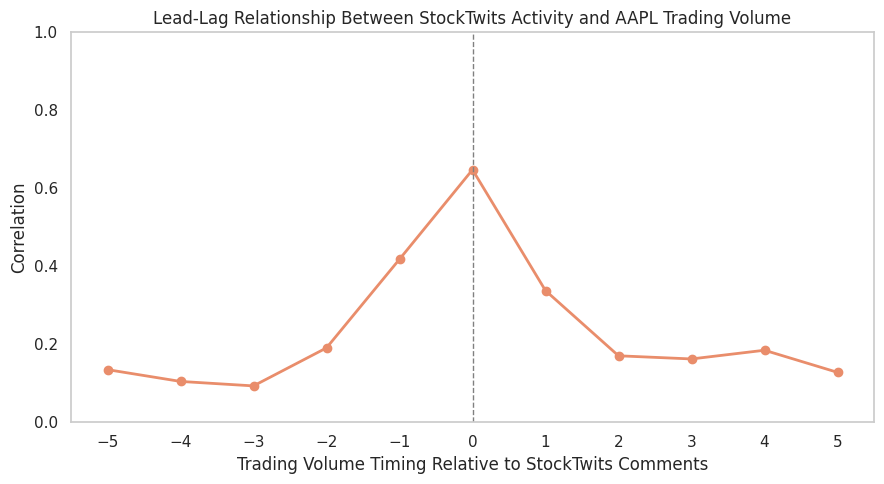

,day,correlation
0,-5,0.13
1,-4,0.10
2,-3,0.09
3,-2,0.19
4,-1,0.42
5,0,0.65
6,1,0.34
7,2,0.17
8,3,0.16
9,4,0.18


In [ ]:
# Compare StockTwits comments with AAPL's trading volume

# Define range from 5 trading days before to 5 trading days after
trading = trading.reset_index()
days = range(-5, 6)
corr_values = []

for day in days:
    corr = trading['comments_vs_usual'].corr(trading['volume_vs_usual'].shift(-day))
    corr_values.append(corr)

lag_corr = pd.DataFrame({'day': days, 'correlation': corr_values})

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(lag_corr['day'], lag_corr['correlation'], marker='o', linewidth=2)
plt.ylim(0, 1)

ax.axvline(x=0, color='gray', linestyle='--', linewidth=1)
ax.set_xticks(range(-5, 6))

ax.set_xlabel('Trading Volume Timing Relative to StockTwits Comments')
ax.set_ylabel('Correlation')
ax.set_title('Lead-Lag Relationship Between StockTwits Activity and AAPL Trading Volume')

ax.grid(False)
plt.tight_layout()
plt.show()

display(lag_corr.round(2))

**Key Takeaways**

*  StockTwits comments and trading volume have the strongest relationship on the same trading day, with a correlation of approximately 0.65, compared with about 0.42 with the previous trading day and 0.34 with the next trading day.

*  The lead-lag analysis can imply that StockTwits activity tends to focus more on current market activity rather than future volume.

### **4.2 Does investor sentiment matter?**

About 74% of the tagged comments are bullish. We want to know if the mood of the comments tells us anything about next-day trading volume, or if only the number of comments is relevant.

*   Bullish share: bullish comments ÷ (bullish + bearish). Comments with no sentiment are not considered.
*   Disagreement: 0 means everyone agrees, 1 means a 50/50 split between bullish and bearish.

We analyze three things:
1.  Is next-day volume higher after more bullish or less bullish days?
2.  Is next-day volume higher after days when investors disagree?
3.  Which matters more for next-day volume: how much people comment, or which way they lean?




**4.2.1 How does investor mood and trading volume change over time?**

We look at how bullishness and trading volume moved over the two years. Both lines go up and down over time, which is why we compare each day with the average of the 30 trading days before it.

In [ ]:
q3 = trading.copy()

# Bullish share vs usual (average of the 30 trading days before), in points
q3['bull_usual'] = q3['bull_share'].rolling(30, min_periods=10).mean().shift(1)
q3['bull_vs_usual'] = (q3['bull_share'] - q3['bull_usual']) * 100

# Disagreement: 0 = everyone agrees, 1 = split 50/50 (tagged comments only)
q3['disagree'] = 1 - abs(q3['bull_share'] - (1 - q3['bull_share']))
q3['disagree_usual'] = q3['disagree'].rolling(30, min_periods=10).mean().shift(1)
q3['disagree_vs_usual'] = (q3['disagree'] - q3['disagree_usual']) * 100

# Next day's volume compared with its usual level (1.0 = typical day)
q3['next_volume_vs_usual'] = q3['volume_vs_usual'].shift(-1)

# Keep only days with all the values we need
q3 = q3.dropna(subset=['bull_vs_usual', 'disagree_vs_usual', 'next_volume_vs_usual'])

colors = sns.color_palette("flare", 6)
q3[['bull_share', 'bull_vs_usual', 'disagree', 'disagree_vs_usual', 'next_volume_vs_usual']].describe().round(2)

,bull_share,bull_vs_usual,disagree,disagree_vs_usual,next_volume_vs_usual
count,532.00,532.00,532.00,532.00,532.00
mean,0.74,-0.19,0.49,0.39,1.00
std,0.14,10.39,0.24,18.60,0.36
min,0.28,-37.67,0.07,-51.33,0.42
25%,0.65,-7.26,0.29,-13.16,0.76
50%,0.78,0.79,0.45,-0.58,0.90
75%,0.85,6.98,0.68,13.08,1.18
max,0.96,26.86,0.99,58.50,2.98


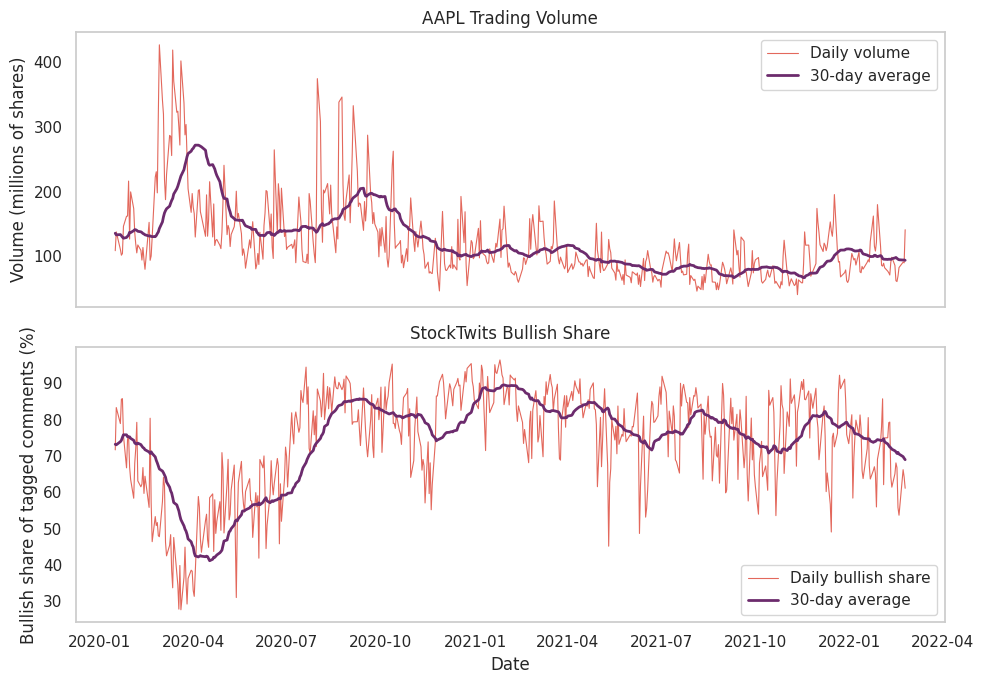

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

# Top: trading volume and its 30-day average
axes[0].plot(q3['date'], q3['volume_millions'], color=colors[1], linewidth=0.8, label='Daily volume')
axes[0].plot(q3['date'], q3['volume_usual'] / 1e6, color=colors[5], linewidth=2, label='30-day average')
axes[0].set_ylabel('Volume (millions of shares)')
axes[0].set_title('AAPL Trading Volume')
axes[0].legend()
axes[0].grid(False)

# Bottom: bullish share and its 30-day average
axes[1].plot(q3['date'], q3['bull_share'] * 100, color=colors[1], linewidth=0.8, label='Daily bullish share')
axes[1].plot(q3['date'], q3['bull_usual'] * 100, color=colors[5], linewidth=2, label='30-day average')
axes[1].set_ylabel('Bullish share of tagged comments (%)')
axes[1].set_title('StockTwits Bullish Share')
axes[1].set_xlabel('Date')
axes[1].legend()
axes[1].grid(False)

plt.tight_layout()
plt.show()

**Key Takeaways**

*   Days with the highest trading volume had the lowest bullishness levels. Then, as optimisism came back, trading slowed down.

*  Bullishness does not have a clear pattern and changes a lot from day to day. It variates often from 10 to 20 points in a day, while the 30-day average moves slowly.

*   Most of the relationship comes at the COVID crash.

**4.2.2 Is trading higher after days when investors disagree?**

A trade needs a buyer and a seller. We check if days with more disagreement than usual between bullish and bearish comments are followed by more trading.

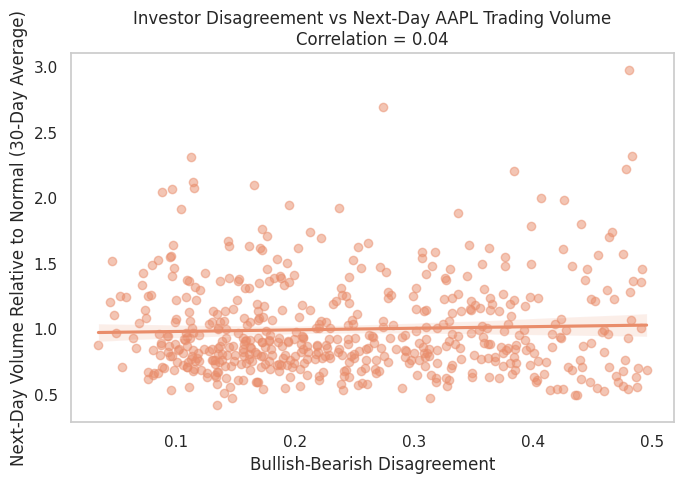

In [ ]:
# Create bullish share, only with tagged comments
trading['bull_share'] = (trading['bullish'] / (trading['bullish'] + trading['bearish']))

# Disagreement: the closer the bullish to 50% are the more disagreement in the market (0 = all tagged comments are bullish, 0.5 = half and half)
trading['disagreement'] = (0.5 - abs(trading['bull_share'] - 0.5))

# Next trading session volume
trading['next_volume_vs_usual'] = (trading['volume_vs_usual'].shift(-1))
disagreement_corr = trading['disagreement'].corr(trading['next_volume_vs_usual'])

fig, ax = plt.subplots(figsize=(7, 5))
sns.regplot(data=trading, x='disagreement', y='next_volume_vs_usual', scatter_kws={'alpha': 0.5}, ax=ax)

ax.set_xlabel('Bullish-Bearish Disagreement')
ax.set_ylabel('Next-Day Volume Relative to Normal (30-Day Average)')
ax.set_title(f'Investor Disagreement vs Next-Day AAPL Trading Volume\n' f'Correlation = {disagreement_corr:.2f}')

plt.tight_layout()
plt.show()

**Key Takeaways**

*   Investor disagreement has a weak positive relationship with next-day AAPL trading volume, with a correlation of 0.04. Therefore, disagreement is not directly related to next-day trading activity which indicates that the number of comments is more important.

**4.2.3 What matters more: how much people comment, or which way they lean?**

This is part of our main hypothesis. Each dot is one trading day. We compare two things with next-day volume: the number of comments and the bullish share. The r value in each title shows how strong the relationship is.

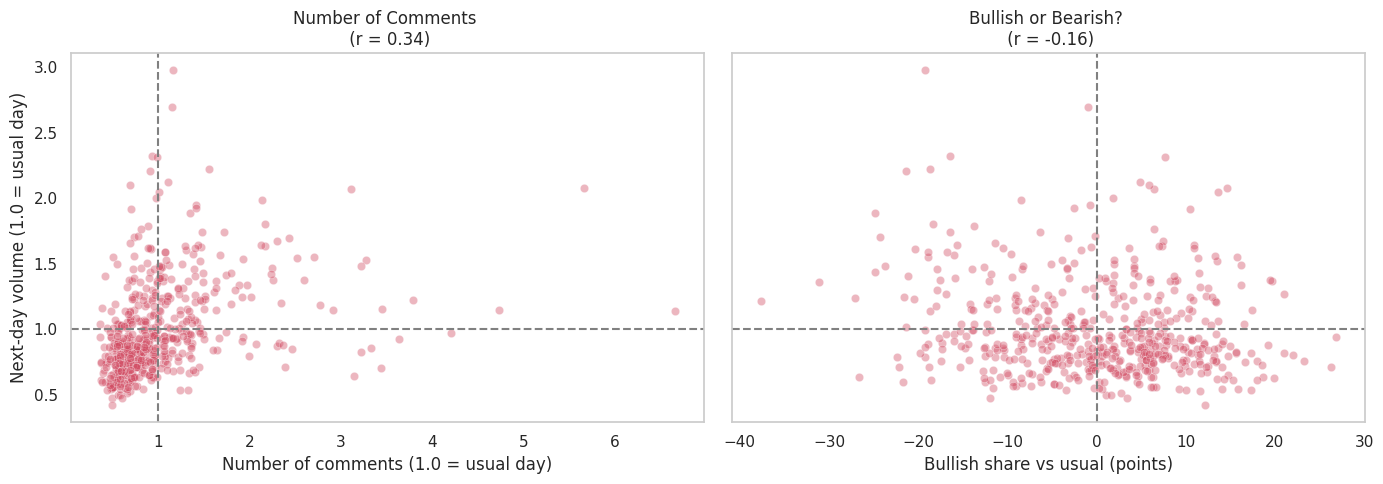

In [ ]:
r_number = q3['comments_vs_usual'].corr(q3['next_volume_vs_usual'])
r_direction = q3['bull_vs_usual'].corr(q3['next_volume_vs_usual'])

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

# Left: how much people comment
sns.scatterplot(x='comments_vs_usual', y='next_volume_vs_usual', data=q3,
                alpha=0.4, color=colors[2], ax=axes[0])
axes[0].axvline(1, color='gray', linestyle='--')   # usual number of comments
axes[0].axhline(1, color='gray', linestyle='--')   # usual volume
axes[0].set_xlabel('Number of comments (1.0 = usual day)')
axes[0].set_ylabel('Next-day volume (1.0 = usual day)')
axes[0].set_title(f'Number of Comments \n (r = {r_number:.2f})')
axes[0].grid(False)

# Right: which way they lean
sns.scatterplot(x='bull_vs_usual', y='next_volume_vs_usual', data=q3,
                alpha=0.4, color=colors[2], ax=axes[1])
axes[1].axvline(0, color='gray', linestyle='--')   # usual bullish share
axes[1].axhline(1, color='gray', linestyle='--')   # usual volume
axes[1].set_xlabel('Bullish share vs usual (points)')
axes[1].set_ylabel('')
axes[1].set_title(f'Bullish or Bearish? \n (r = {r_direction:.2f})')
axes[1].grid(False)

plt.tight_layout()
plt.show()

**Key Takeaways**

*   How much people comment matters more than which way they lean. The number of comments has a correlation of 0.34 with next-day volume, while the bullish share has a correlation of -0.16.
*   When the number of comments is above its usual level, next-day volume also tends to be above its usual level.

**4.2.4 Once we know the number of comments, does sentiment add anything?**

The past graph looks at each factor separately. Here we look at both together: days with more or fewer comments than usual and days that were more or less bullish than usual. Each cell shows the average next-day volume.

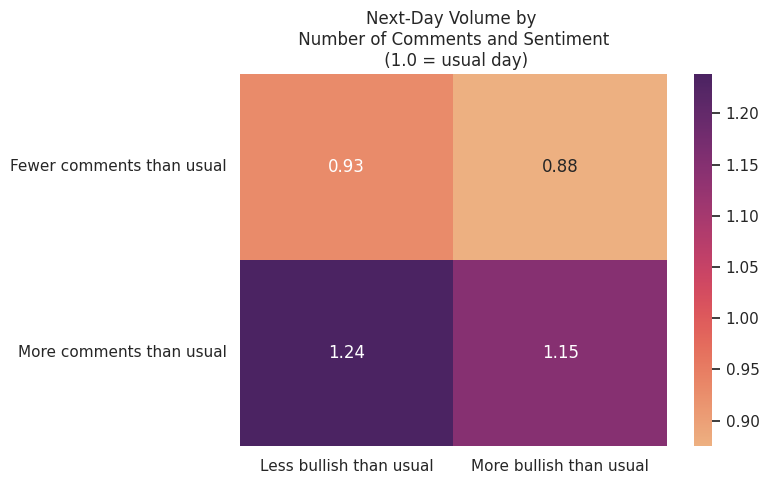

bull_level,Less bullish than usual,More bullish than usual
comments_level,,
Fewer comments than usual,160,186
More comments than usual,92,94


In [ ]:
q3['comments_level'] = 'More comments than usual'
q3.loc[q3['comments_vs_usual'] < 1, 'comments_level'] = 'Fewer comments than usual'

q3['bull_level'] = 'More bullish than usual'
q3.loc[q3['bull_vs_usual'] < 0, 'bull_level'] = 'Less bullish than usual'

heat = q3.groupby(['comments_level', 'bull_level'])['next_volume_vs_usual'].mean().unstack()

fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(heat, annot=True, fmt='.2f', cmap=flare, ax=ax)
ax.set_xlabel('')
ax.set_ylabel('')
ax.set_title('Next-Day Volume by \n Number of Comments and Sentiment \n (1.0 = usual day)')
plt.tight_layout()
plt.show()

# Days in each cell
q3.groupby(['comments_level', 'bull_level'])['next_volume_vs_usual'].count().unstack()

**Key Takeaways**

*   The number of comments makes the biggest difference. After days with more comments than usual (30-day moving average), next-day volume was 15% to 23% above normal (1.15 and 1.23). After days with fewer comments than usual, it was 8% to 12% below normal (0.88 and 0.92).
*   Sentiment adds very little.
*   When comments are above their 30-day average, next-day volume is expected to be about 15% to 23% above normal.

In [ ]:
# Back to the white style for the next sections
#sns.set_theme(style="whitegrid", palette="flare")

### **4.3 When do comments occur? Does it matter?**

**4.3.1.** Weekday and hour heatmap: on which days and at what times do investors post the most comments about Apple?



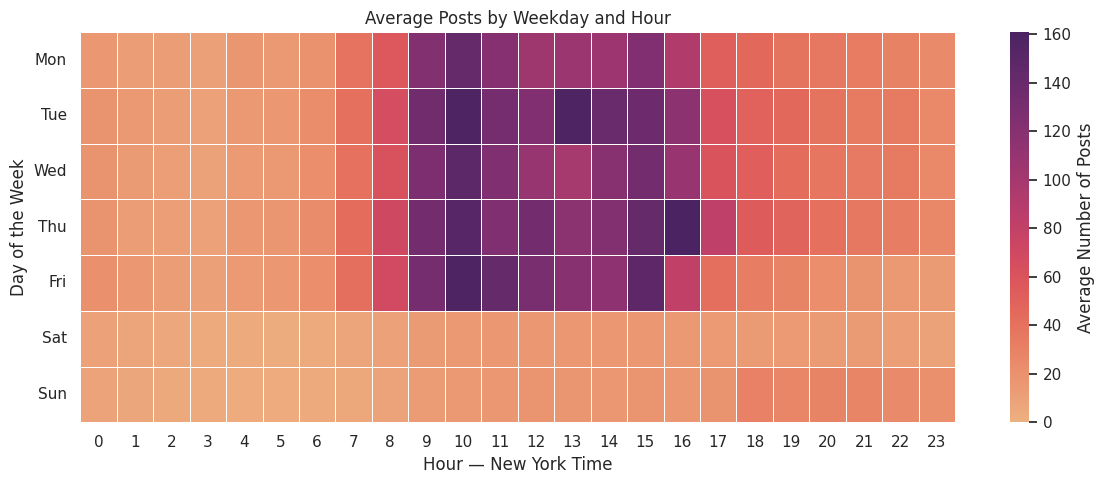

,Average comments per day
Mon,1377.0
Tue,1606.0
Wed,1464.0
Thu,1634.0
Fri,1418.0
Sat,269.0
Sun,358.0


,Average comments per day
Weekdays,1500.0
Weekends,314.0


In [ ]:
posts = stocktwits_df.copy()
posts['date'] = pd.to_datetime(posts['date'])

# Exclude the first and last dates because they may be incomplete
dates = pd.date_range(
    posts['date'].min() + pd.Timedelta(days=1),
    posts['date'].max() - pd.Timedelta(days=1)
)

# Count comments for each date and hour
hourly = pd.crosstab(posts['date'], posts['hour'])

# Include dates and hours with zero comments
hourly = hourly.reindex(
    index=dates,
    columns=range(24),
    fill_value=0
)

# Calculate average comments for each weekday and hour
weekly = hourly.groupby(hourly.index.dayofweek).mean()
weekly = weekly.reindex(range(7))
weekly.index = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']

# Create the heatmap
plt.figure(figsize=(12, 5))

sns.heatmap(
    weekly,
    cmap='flare',
    vmin=0,
    linewidths=0.5,
    linecolor='white',
    cbar_kws={'label': 'Average Number of Posts'}
)

plt.title('Average Posts by Weekday and Hour')
plt.xlabel('Hour — New York Time')
plt.ylabel('Day of the Week')
plt.xticks(rotation=0)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

# Table summary to suppor graph
per_day = weekly.sum(axis=1).round(0)
day_table = pd.DataFrame({'Average comments per day': per_day})
display(day_table)

# Weekdays vs weekends
weekday_avg = per_day[['Mon', 'Tue', 'Wed', 'Thu', 'Fri']].mean()
weekend_avg = per_day[['Sat', 'Sun']].mean()
summary = pd.DataFrame({'Average comments per day': [weekday_avg, weekend_avg]},
                       index=['Weekdays', 'Weekends']).round(0)
display(summary)

**Key Takeaways**

*  Weekdays average approximately 1,500 posts, compared with 313 on weekends, which is about 4.8x more.
*  Discussions usually occurs when the market is open (9am to 4:00pm aprox), but the Thursdays from 4–5 p.m has the highest level of activity, with approximately 161 posts.

**4.3.2. When do comments come when earnings releases occur?**

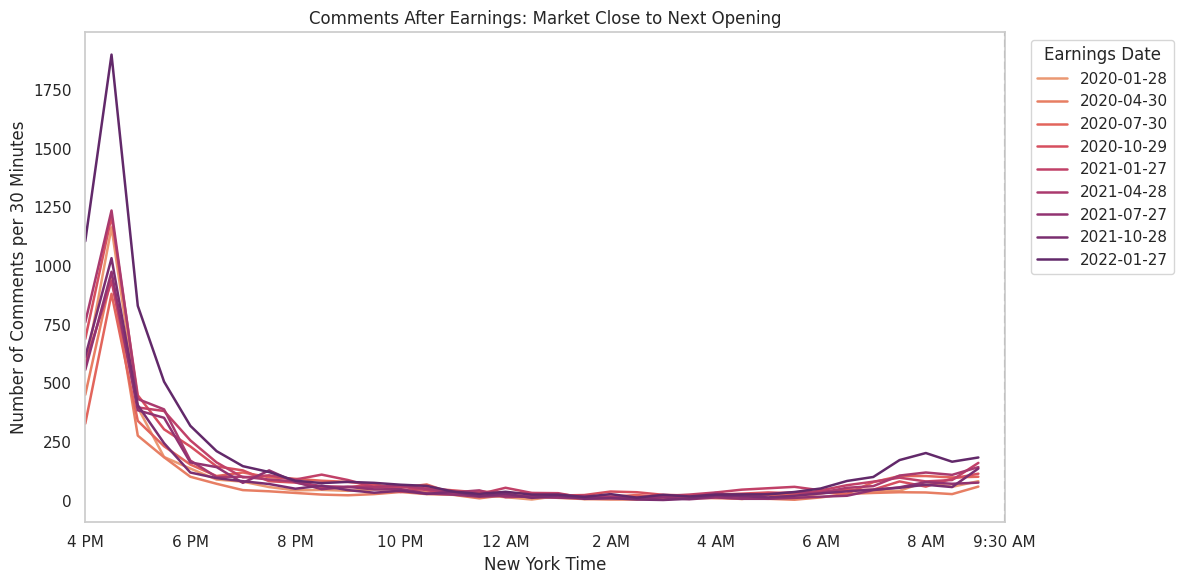

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

posts = stocktwits_df.copy()

# Join the New York date and time
posts['date'] = pd.to_datetime(posts['date'])
posts['timestamp'] = pd.to_datetime(
    posts['date'].dt.strftime('%Y-%m-%d') + ' ' + posts['time'].astype(str)
)

if 'date' in trading.columns:
    trading_days = pd.to_datetime(trading['date'])
else:
    trading_days = pd.to_datetime(trading.index)

trading_days = pd.DatetimeIndex(trading_days).sort_values()

earnings_dates = pd.to_datetime([
    '2020-01-28', '2020-04-30', '2020-07-30', '2020-10-29',
    '2021-01-27', '2021-04-28', '2021-07-27', '2021-10-28',
    '2022-01-27'
])

colors = sns.color_palette('flare', len(earnings_dates))
plt.figure(figsize=(12, 6))

for i, day in enumerate(earnings_dates):

    next_days = trading_days[trading_days > day]

    if len(next_days) == 0:
        continue

    next_day = next_days[0]

    # Comments from 4 PM until the next opening
    start = day + pd.Timedelta(hours=16)
    end = next_day + pd.Timedelta(hours=9, minutes=30)

    selected = posts[
        (posts['timestamp'] >= start)
        & (posts['timestamp'] < end)
    ].copy()

    # Count posts in each half-hour
    selected['half_hour'] = selected['timestamp'].dt.floor('30min')
    counts = selected.groupby('half_hour').size()

    times = pd.date_range(
        start, end, freq='30min', inclusive='left'
    )

    counts = counts.reindex(times, fill_value=0)
    hours = (times - start).total_seconds() / 3600

    plt.plot(
        hours,
        counts.values,
        label=day.strftime('%Y-%m-%d'),
        color=colors[i],
        linewidth=1.8
    )

plt.axvline(17.5, color='gray', linestyle='--')

plt.xticks(
    [0, 2, 4, 6, 8, 10, 12, 14, 16, 17.5],
    ['4 PM', '6 PM', '8 PM', '10 PM', '12 AM',
     '2 AM', '4 AM', '6 AM', '8 AM', '9:30 AM']
)

plt.xlim(0, 17.5)
plt.title('Comments After Earnings: Market Close to Next Opening')
plt.xlabel('New York Time')
plt.ylabel('Number of Comments per 30 Minutes')
plt.legend(
    title='Earnings Date',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

plt.tight_layout()
plt.show()

**Key Takeaways**
- The session following an earnings release averages 5,897 assigned comments vs. 1,606 on regular sessions.
- Approximately 71% of those comments arrive before the opening, compared with 46% on regular sessions.

### **4.4 How does StockTwits activity change around Apple earnings announcements?**

Since earnings announcements usually significantly affect the stock, we focus on the five trading days before and after the announcement dates to understand how these events affect StockTwits activity. We observe whether comments rise before or after earnings, which event day has the highest activity, and how much higher Day +1 activity is compared with the average activity during the five days before earnings.


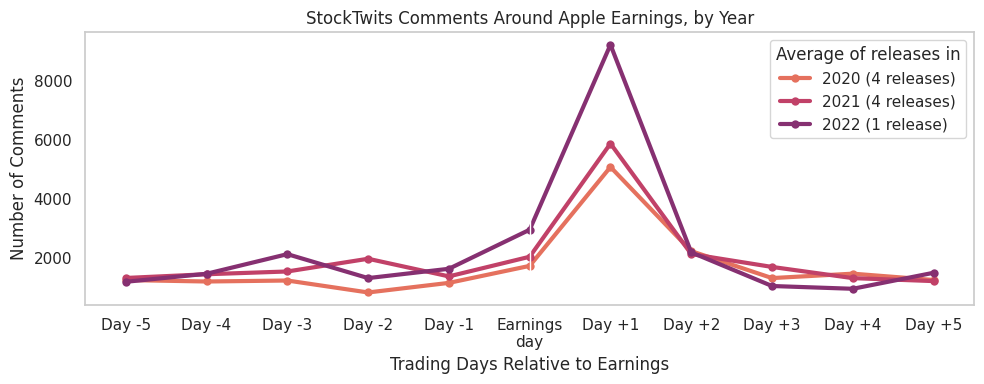

event_day,-5,-4,-3,-2,-1,0,1,2,3,4,5
group,,,,,,,,,,,
2020 (4 releases),1272.0,1223.0,1256.0,853.0,1176.0,1750.0,5088.0,2247.0,1338.0,1487.0,1274.0
2021 (4 releases),1342.0,1468.0,1561.0,1990.0,1395.0,2058.0,5878.0,2149.0,1714.0,1337.0,1237.0
2022 (1 release),1213.0,1484.0,2146.0,1338.0,1652.0,2971.0,9214.0,2206.0,1071.0,977.0,1518.0


,avg_comments
group,
2020 (4 releases),4.4
2021 (4 releases),3.8
2022 (1 release),5.9


In [ ]:
event_windows = []

for earnings_date in earnings_dates:

    match = trading.index[trading['date'] == earnings_date].tolist()

    if len(match) > 0:
        i = match[0]
        if i >= 5 and i + 5 < len(trading):
            window = trading.loc[i-5:i+5, ['date', 'n_posts']].copy()
            window['event_day'] = range(-5, 6)
            window['earnings_date'] = earnings_date
            event_windows.append(window)

# Combine all earnings windows
earnings_window = pd.concat(event_windows, ignore_index=True)

# Group the releases by year (the label shows how many releases each year has)
earnings_window['year'] = earnings_window['earnings_date'].dt.year
labels = {2020: '2020 (4 releases)', 2021: '2021 (4 releases)', 2022: '2022 (1 release)'}
earnings_window['group'] = earnings_window['year'].map(labels)

# Average number of comments for each year and relative day
earnings_by_year = (earnings_window.groupby(['group', 'event_day'])['n_posts']
                    .mean().reset_index(name='avg_comments'))

fig, ax = plt.subplots(figsize=(10, 4))

sns.lineplot(data=earnings_by_year, x='event_day', y='avg_comments', hue='group',
             palette=sns.color_palette('flare', 3), linewidth=3, marker='o',
             markeredgewidth=0, ax=ax)

# Earnings day
ax.axvline(x=0, color='white', linewidth=1)


ax.set_xticks(range(-5, 6))
ax.set_xticklabels(['Day -5', 'Day -4', 'Day -3', 'Day -2', 'Day -1', 'Earnings\nday', 'Day +1', 'Day +2', 'Day +3', 'Day +4', 'Day +5'])

ax.set_xlabel('Trading Days Relative to Earnings')
ax.set_ylabel('Number of Comments')
ax.set_title('StockTwits Comments Around Apple Earnings, by Year')
ax.legend(title='Average of releases in')

ax.grid(False)

plt.tight_layout()
plt.show()

display(earnings_by_year.pivot(index='group', columns='event_day', values='avg_comments').round(0))

# How many times the pre-earnings level is Day +1?
before = earnings_by_year[earnings_by_year['event_day'].between(-5, -1)].groupby('group')['avg_comments'].mean()
day1 = earnings_by_year[earnings_by_year['event_day'] == 1].set_index('group')['avg_comments']

(day1 / before).round(1)

**Key Takeaways**

*   Comments spike the day after earnings. On Day +1, there were about 4.4 times more comments than in the five days before earnings in 2020, 3.8 times more in 2021, and 5.9 times more in 2022 (first earnings release in 2022).
*   Apple reports after the market closes, so most of the reaction is counted on the next trading day.


### **4.5 Do bullish, bearish or untagged comments get more attention?**

Do comments where the user takes a side (bullish or bearish) get more likes and replies than comments with no tag?

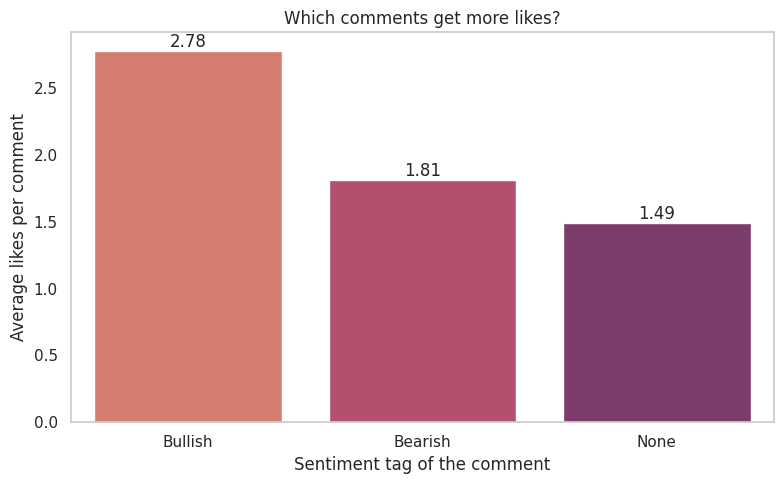

,Average likes,Average replies
sentiment,,
Bullish,2.78,1.25
Bearish,1.81,1.88
None,1.49,2.95


In [ ]:
# Avg likes and avg replies for each type of comment (Bullish, Bearish and None)
likes_by_tag = stocktwits_df.groupby('sentiment')['likes'].mean()
replies_by_tag = stocktwits_df.groupby('sentiment')['replies'].mean()

# Table, round anwers
tags = pd.DataFrame({'Average likes': likes_by_tag, 'Average replies': replies_by_tag})
tags = tags.loc[['Bullish', 'Bearish', 'None']].round(2)

fig, ax = plt.subplots(figsize=(8, 5))

# Chart: avg likes per comment for each type of comment (bullish, bearish, none)
sns.barplot(x=tags.index, y=tags['Average likes'], hue=tags.index,
            palette=sns.color_palette("flare", 3), legend=False, ax=ax)

# We want to add the numbers on top of each bar so we can read the chart easier
for bars in ax.containers:
    ax.bar_label(bars, fmt='%.2f')

ax.set_title('Which comments get more likes?')
ax.set_xlabel('Sentiment tag of the comment')
ax.set_ylabel('Average likes per comment')

ax.grid(False)
plt.tight_layout()
plt.show()

display(tags)

**Key Takeaways**

- Bullish comments get the most likes (2.78 on average), followed by bearish (1.81) and untagged comments (1.49).

- A bullish comment gets almost twice as many likes as an untagged one (2.78 vs 1.49) so comments that take a side, especially an optimistic one, get more attention on the chart.

### **4.6 Does trading stay high after a volume spike?**

After the 10 days with the highest trading volume, does volume and the number of comments drop back to normal right away or stay high for several days?

We wanted to see what happens after a day when a lot of Apple shares are traded. We picked the 10 days with the highest trading volume compared to its 30-day moving averafe and looked at the next 14 trading days. Day 0 is the spike day.

In [ ]:
# when i didn't do copy it gave a mistake and told me to create a copy
# so i am making a copy of the trading data so we don't change the original table
q = trading.copy()
if 'date' not in q.columns:
    q = q.reset_index()

# Finding the 10 days with the highest volume compared with a usual day
top10 = q.nlargest(10, 'volume_vs_usual').index

# Tracking trading volume and comments for 14 days after each spike
# create an empty list so it will save the data
rows = []
for i in top10:
    if i + 14 < len(q):
        for day in range(0, 15):
            rows.append({'spike_date': q.loc[i, 'date'],
                         'day': day,
                         'volume_vs_usual': q.loc[i + day, 'volume_vs_usual'],
                         'comments_vs_usual': q.loc[i + day, 'comments_vs_usual']})

after = pd.DataFrame(rows)

# Avg of the 10 spikes for each day (1.0 is the usual for a day)
after_avg = after.groupby('day')[['volume_vs_usual', 'comments_vs_usual']].mean().round(2)
after_avg

,volume_vs_usual,comments_vs_usual
day,,
0,2.31,2.59
1,1.90,2.12
2,1.45,1.78
3,1.25,1.21
4,1.20,1.21
5,1.35,1.49
6,1.40,1.59
7,1.24,1.36
8,1.35,1.29


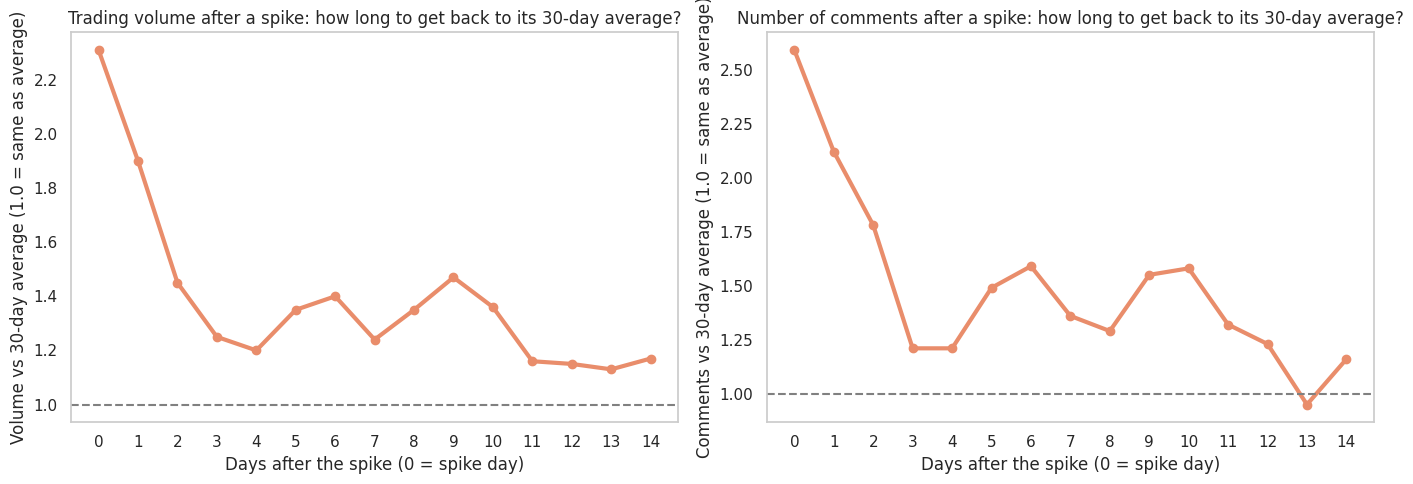

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left chart (trading volume)
axes[0].plot(after_avg.index, after_avg['volume_vs_usual'], marker='o', linewidth=3)
# adding a line at 1 to show the usual level
axes[0].axhline(1, color='gray', linestyle='--')
# Show all 15 days on the x-axis
axes[0].set_xticks(range(0, 15))
axes[0].set_title('Trading volume after a spike: how long to get back to its 30-day average?')
axes[0].set_xlabel('Days after the spike (0 = spike day)')
axes[0].set_ylabel('Volume vs 30-day average (1.0 = same as average)')
axes[0].grid(False)

# Right chart (number of comments)
axes[1].plot(after_avg.index, after_avg['comments_vs_usual'], marker='o', linewidth=3)
axes[1].axhline(1, color='gray', linestyle='--')
axes[1].set_xticks(range(0, 15))
axes[1].set_title('Number of comments after a spike: how long to get back to its 30-day average?')
axes[1].set_xlabel('Days after the spike (0 = spike day)')
axes[1].set_ylabel('Comments vs 30-day average (1.0 = same as average)')
axes[1].grid(False)

plt.tight_layout()
plt.show()

**Key Takeaways**

*   1.0 means a normal day (30-day moving average - represented by dashed line), 2.0 means double and 1.25 means 25% more than normal.
*   Spike day: trading volume was more than double a normal day (2.31 vs 1.0) and the number of comments was even higher (2.59 vs 1.0).
*  Within 3 days, both calm down a lot. By day 3, volume is only about 25% above a normal day (1.25), and comments are about 21% above (1.21).
*  Neither goes fully back to normal in the 14 days we looked at. Volume stays about 15% to 47% above a normal day so the excitement fades quickly but not completely.


### **4.7 Did the COVID crash change how people commented on StockTwits?**

Compared with the time before and after the COVID crash (Feb 2020 - Apr 2020) did people write more or fewer comments per day during the crash and were those comments less bullish?

- We wanted to see if the COVID crash changed how much people commented and how bullish they were. We compared the days before, during (Feb 20 to Apr 7, 2020) and after the crash. The left chart shows the average daily comments and different users and the right shows average bullish share.

In [ ]:
# We want to see how many different users commented in each session
users_per_day = stocktwits_df.groupby('session_date')['user_id'].nunique().reset_index()
users_per_day.columns = ['date', 'unique_users']

# Copying the data again
crash_data = trading.copy()
crash_data = crash_data.merge(users_per_day, on='date')

# Splitting the days into three groups by date
# COVID crash: Feb 20, 2020 (sudden drop) to April 7, 2020 (crash ends)
before_crash = crash_data[crash_data['date'] < '2020-02-20'].copy()
crash_days = crash_data[(crash_data['date'] >= '2020-02-20') & (crash_data['date'] <= '2020-04-07')].copy()
after_crash = crash_data[crash_data['date'] > '2020-04-07'].copy()

# Add the period names
before_crash['period'] = 'Before'
crash_days['period'] = 'During'
after_crash['period'] = 'After'

# Put the three periods together
all_days = pd.concat([before_crash, crash_days, after_crash])

# Bullish share as a percent
all_days['bullish_pct'] = all_days['bull_share'] * 100

crash_table = all_days.groupby('period')[['n_posts', 'unique_users', 'bullish_pct']].mean()
crash_table = crash_table.loc[['Before', 'During', 'After']].round(1)
crash_table.columns = ['Comments', 'Different users', 'Bullish share (%)']
crash_table

,Comments,Different users,Bullish share (%)
period,,,
Before,1332.8,567.0,71.3
During,1520.1,609.4,43.7
After,1720.3,737.4,76.5


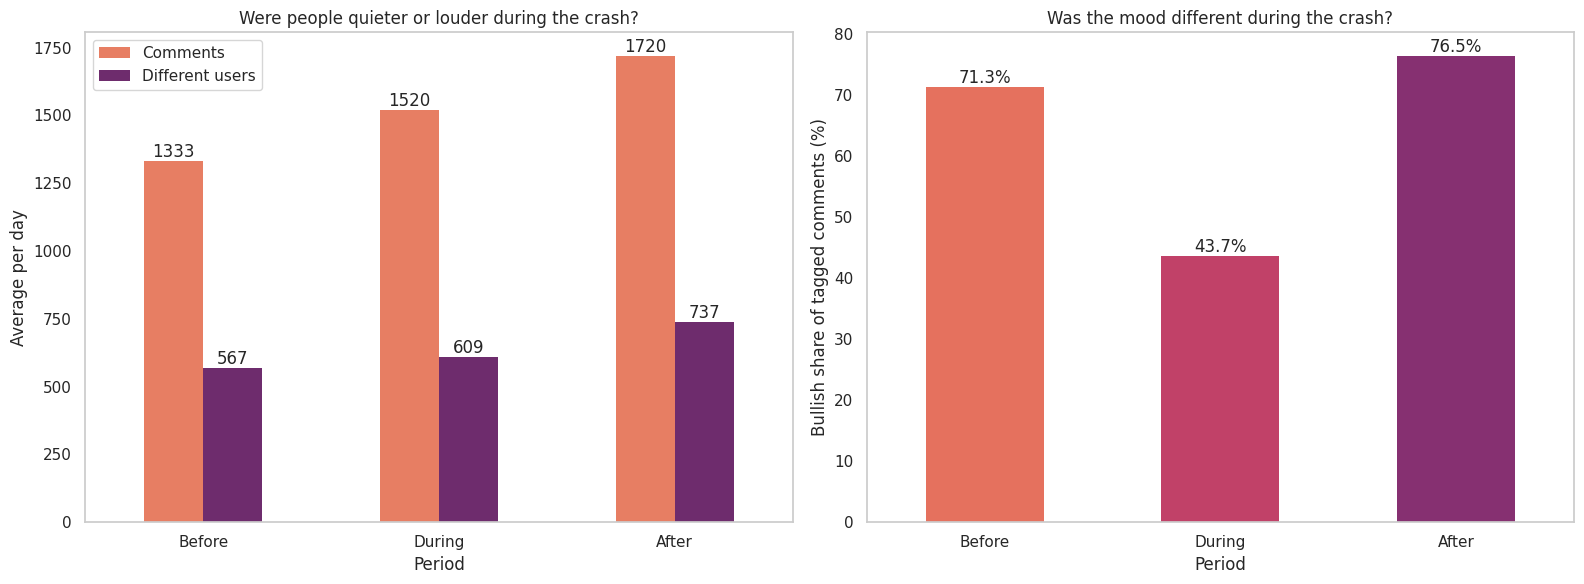

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left chart: comments and different users
crash_table[['Comments', 'Different users']].plot(kind='bar', ax=axes[0], color=[flare(0.2), flare(0.85)], rot=0, linewidth=0)
for bars in axes[0].containers:
    axes[0].bar_label(bars, fmt='%.0f')
axes[0].set_title('Were people quieter or louder during the crash?')
axes[0].set_xlabel('Period')
axes[0].set_ylabel('Average per day')
axes[0].grid(False)

# Right chart: bullish share
crash_table['Bullish share (%)'].plot(kind='bar', ax=axes[1], color=sns.color_palette("flare", 3), rot=0, linewidth=0)
for bars in axes[1].containers:
    axes[1].bar_label(bars, fmt='%.1f%%')
axes[1].set_title('Was the mood different during the crash?')
axes[1].set_xlabel('Period')
axes[1].set_ylabel('Bullish share of tagged comments (%)')
axes[1].grid(False)

ax.grid(False)
plt.tight_layout()
plt.show()

**Key Takeaways:**

- During the crash, only 43.7% of tagged comments were bullish, compared with 71.3% before and 76.5% after. People were much less optimistic when the market panicked.

- The number of comments didn't jump during the crash. There were about 1,520 per day which is more than before (1,333) but less than after (1,720). The mood changed,but the amount of chatter didnt change.

## **5. Conclusion**

We wanted to know if StockTwits comments about Apple can tell us how busy trading will be the next day. We compared each day with its 30-day average, looked at the number of comments and their sentiment, and checked what happens around earnings and during the COVID crash.

### **5.1 Findings**

1.  **Comments and volume move together, but mostly on the same day:** the correlation is 0.65 on the same day, 0.42 with the day before and 0.35 with the next day. Comments react to the actual trading more than leading the next one.

2.  **More comments today, more trading tomorrow:** when the number of comments was above its 30-day moving average, next-day volume was 15% to 23% above normal. After days with fewer comments, it was 8% to 12% below normal.

3.  **The number of comments matters more than investor sentiment:** the number of comments has a correlation of 0.35 with next-day volume, the bullish share -0.16, and disagreement only 0.04.

4.  **How COVID was different:** during COVID, less than half of the tagged comments were bullish (44%). Befor COVID 71% were bullish and after COVID, 77% but the number of comments didn't vary. The days with the highest volume were during COVID crash (Feb 2020 - Apr 2020).

5.  **Earnings days have a big effect on StockTwits:** the day after earnings are about 4 to 6 times above average, and most of them are written before the market opens. Comments go back to normal within about three days.

6.  **Spikes don't last:** after the 10 biggest volume days, volume and comments drop a lot within three days, but stay a bit above normal for two weeks.

**Our hypothesis is partly supported:** there is a clear relationship between comments and next-day volume, but it is not strong enough to work as a forecast. These results show association, not causation, and may be specific to Apple and the 2020 to 2022 period.

### **5.2 Future Steps**

*   Test if comments still help when we already know today's volume, (ie. simple regression)
*   Calculate p-values for our main correlations.
*   Repeat the analysis without earnings days and without the COVID crash, to see if the rule holds on normal days.
*   Try other stocks and other years, to see if the pattern is specific to Apple.
*   Look at the text of the comments. About half have no sentiment tag, so reading the text could give a better measure of mood.

### **5.3 Business Recommendations**

*   **Brokers and investment teams:** track the daily number of Apple comments compared with its 30-day average. When it is above average, use a guidance to the next day at the office to be busier (about 15% to 23% more volume). This can help plan staff and system capacity and stress level.
*   **Plan for the day after earnings:** It is the most predictable spike in both comments and trading, and it is known months in advance.
*   **Investors:** do not use bullish or bearish sentiment to decide trades. It mostly follows what the price already did. A sharp drop in bullishness is a sign of stress in the market, not a signal to buy or sell.
*   **Do not expect an exact forecast:** Comments tell you that tomorrow may be busier, not by exactly how much.

## **6. Challenges**

*  **Matching comments to the correct trading day:** our main challenge was to match each comment to its correct session date, considering Fridays after the market closed, weekends, and holidays.

*  **Different file structures:** the 62 CSV files had 14 or 15 columns in different orders. We kept only the columns all files had in common and selected them by name before combining them.

*  **Information hidden in text and time zones:** sentiment, likes, replies and user details were inside long text columns, so we extracted each one into its own column. Timestamps were in UTC, so we converted them to New York time to math it with the stock market's schedule.

# **7. References**

[Liz Frazier, "The Coronavirus Crash Of 2020, And The Investing Lesson It Taught Us", Forbes, February 11, 2021](https://www.forbes.com/sites/lizfrazierpeck/2021/02/11/the-coronavirus-crash-of-2020-and-the-investing-lesson-it-taught-us/)

[StockTwits_2020_2022_Raw Data Set, Kaggle](https://www.kaggle.com/datasets/frankcaoyun/stocktwits-2020-2022-raw)

[Apple Inc. (AAPL) Historical Data, Yahoo Finance](https://finance.yahoo.com/quote/AAPL/history)

[yfinance Python Package](https://pypi.org/project/yfinance/)

[Apple Investor Relations](https://investor.apple.com)

[Mohammad Soltanieh-ha, "BA780 - Introduction to Data Analytics", Colab Notebooks, Fall 2026](https://github.com/soltaniehha/Intro-to-Data-Analytics)

[DataCamp Modules](https://app.datacamp.com/learn/assignments)

[Seaborn Color Palettes](https://seaborn.pydata.org/tutorial/color_palettes.html)

[Chart Ideas](https://seaborn.pydata.org/examples/index.html)

# **8. Generative AI Disclosure**

We used Claude (Anthropic) as a coding and writing assistant. We ran all the code on our own data, checked every output, and edited all text before using it. The team made all final decisions about the question, the method and the conclusions.

**Who did each part**
*  Introduction, data cleaning, and conclusion: all
*  Questions 4.1, 4.2.2 and 4.4: Zoe
*  Question 4.2: Alicia
*  Question 4.3: Ricardo
*  Question 4.5, 4.6 and 4.7: Almira

**How did we use AI?**

*   **Problem definition:** the team defined the question together. After the TA's feedback, we used Claude to suggest how to add success criteria and business decisions, and to check grammar.

*   **Data cleaning:** we started brainstorming with Claude on how to start the data cleaning phase and structure it. We wanted to implement the coding skills we had learned from DataCamp and in class, that we actually could understand, even if it was not the most optimized code. For each problem (loading the files with different structures, finding common columns, extracting sentiment, likes and user information from text columns, and assigning each comment to a trading session), we first wrote down the logic behind it and the code we thought would solve it, and debugged it with Claude.

*   **Questions and charts:** each member used Claude to write and fix chart code, explain what the code does, and suggest ways to group the data.

*   **Writing:** we used Claude to check grammar and spelling throughout the notebook.
